In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import random
from PIL import Image

sys.path.append('/mnt/IXCM')

from DWT import DWT_2D
from IXCM import IXCNet

In [2]:
class TB11KDataset(Dataset):
    def __init__(self, list_path, img_root_path, transform=None):
        """
        Args:
            list_path: txt索引文件路径 (e.g., ./TB11K/lists/TBX11K_train.txt)
            img_root_path: 图片根目录 (e.g., ./TB11K/img)
            transform: 图片预处理
        """
        self.img_root_path = img_root_path
        self.transform = transform
        self.img_paths = []
        self.labels = []

        with open(list_path, 'r') as f:
            lines = f.readlines()
            for line in lines:
                # 假设txt格式为: "folder/filename.png label" 或 纯路径
                # 这里我们只取第一部分的路径字符串
                parts = line.strip().split()
                rel_path = parts[0]
                
                # 路径修正：TB11K txt中有时包含 'imgs/' 前缀，需根据实际情况调整
                # 你的描述是图片在 ./TB11K/img/health 等，所以我们拼接路径
                full_path = os.path.join(self.img_root_path, rel_path)
                
                # 标签逻辑: health/sick -> 0 (Non-TB), tb -> 1 (TB)
                # 检查路径字符串中是否包含目录名
                # 注意：根据你的描述，sick是患病非结核，health是健康，都算0
                # tb是结核，算1
                # 路径通常包含 'health', 'sick', 'tb' 字符串
                if '/tb/' in rel_path or rel_path.startswith('tb/'):
                    label = 1.0
                else:
                    label = 0.0
                
                self.img_paths.append(full_path)
                self.labels.append(label)

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        label = self.labels[idx]

        # 打开图片并转为灰度 (你的DenseNet修改了conv0接受1通道)
        try:
            image = Image.open(img_path).convert('L') 
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            # 返回一个黑图防止崩溃，或者你可以选择跳过
            image = Image.new('L', (256, 256))

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor([label], dtype=torch.float32)

In [3]:
def visualize_evidence_explainability(model, dwt_module, val_loader, class_names, device, sample_idx=0, batch_id=1):
    """
    Args:
        model: 训练好的 IXCNet (必须 img_dec=True)
        dwt_module: 外部实例化的 DWT_2D 模块
        val_loader: 验证集 DataLoader
        class_names: 类别名称列表 (如 ['Atelectasis', 'Cardiomegaly', ...])
        device: 'cuda' or 'cpu'
        sample_idx: Batch 中要看哪张图 (默认第0张)
    """
    model.eval()
    dwt_module.eval()
    
    # 1. 获取一个 Batch 的数据
    target_batch_idx = batch_id 

    images = None
    labels = None
    
    for i, (imgs, lbls) in enumerate(val_loader):
        if i == target_batch_idx:
            images = imgs
            labels = lbls
            break # 找到后立即停止，节省时间
    # images, labels = next(iter(val_loader))
    images = images.to(device)
    
    # 2. 外部分解：获取可视化的 s 和 a
    with torch.no_grad():
        # s: [B, 1, 128, 128], lh/hl/hh: [B, 1, 128, 128]
        s_tensor, lh, hl, hh = dwt_module(images)
        a_tensor = lh + hl
        
    # 3. 模型推理：获取 alphas 和 betas
    with torch.no_grad():
        # 这里需要注意：你的 forward 修改后返回了 5 个值，或者如果你没改 forward，
        # 就只返回 3 个值，这里按标准的 alphas, betas, outs 接收
        # 只要保证 images 是 img_dec=True 模式进去的即可
        output = model(images)
        alphas = output[0] # [B, 2 * num_classes]
        betas = output[1]  # [B, 2 * num_classes]
        
    # --- 数据解包逻辑 (Crucial Step) ---
    # 你的 forward 循环逻辑是：
    # for i in range(classes):
    #     cat(alpha_s)
    #     cat(alpha_a)
    # 所以 alphas 的形状是 [B, 10] (假设5类)，顺序是: S_c0, A_c0, S_c1, A_c1, ...
    
    num_classes = len(class_names)
    b_idx = sample_idx
    
    # 提取当前样本的 alpha/beta
    curr_alphas = alphas[b_idx].cpu().numpy() # [2 * num_classes]
    curr_betas = betas[b_idx].cpu().numpy()
    
    # 利用切片分离 Structure 和 Appearance 的证据
    # 偶数索引 (0, 2, 4...) 是 Structure
    alpha_s_vals = curr_alphas[0::2] 
    beta_s_vals = curr_betas[0::2]
    
    # 奇数索引 (1, 3, 5...) 是 Appearance
    alpha_a_vals = curr_alphas[1::2]
    beta_a_vals = curr_betas[1::2]
    
    # 计算对应的概率 (Expected Probability = alpha / (alpha + beta))
    prob_s = alpha_s_vals / (alpha_s_vals + beta_s_vals)
    prob_a = alpha_a_vals / (alpha_a_vals + beta_a_vals)

    # --- 开始绘图 ---
    # 准备图像数据 (转为 numpy 并去掉 batch 维)
    img_orig = images[b_idx].permute(1, 2, 0).cpu().numpy().squeeze()
    img_s = s_tensor[b_idx].permute(1, 2, 0).cpu().numpy().squeeze()
    img_a = a_tensor[b_idx].permute(1, 2, 0).cpu().numpy().squeeze()
    curr_labels = labels[b_idx].numpy()
    
    # 设置画布：3列 (原图, 结构流S, 纹理流A)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), gridspec_kw={'height_ratios': [1.5, 1]})
    plt.subplots_adjust(wspace=0.3, hspace=0.3)
    
    # === 第一行：图像展示 ===
    
    # 1. Original Image
    axes[0, 0].imshow(img_orig, cmap='gray')
    print(curr_labels)
    axes[0, 0].set_title(f"Original Input\nGT: {[class_names[i] for i in range(num_classes) if curr_labels[i]==1]}", fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    # 2. Structure Image (S)
    axes[0, 1].imshow(img_s, cmap='gray')
    axes[0, 1].set_title("Structure Stream (s)\n(Low Frequency / Shapes)", fontsize=14, fontweight='bold', color='blue')
    axes[0, 1].axis('off')
    
    # 3. Appearance Image (A)
    axes[0, 2].imshow(img_a, cmap='gray')
    axes[0, 2].set_title("Appearance Stream (a)\n(High Frequency / Textures)", fontsize=14, fontweight='bold', color='red')
    axes[0, 2].axis('off')
    
    # === 第二行：证据/概率 条形图 ===
    
    # 辅助函数：绘制条形图
    def plot_bar(ax, values, probs, color, title):
        y_pos = np.arange(num_classes)
        # 画概率条
        bars = ax.barh(y_pos, probs, align='center', color=color, alpha=0.7)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(class_names, fontsize=12)
        ax.invert_yaxis()  # 让第一个类别在最上面
        ax.set_xlabel('Expected Probability: α / (α + β)', fontsize=12)
        ax.set_xlim(0, 1.0)
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.grid(axis='x', linestyle='--', alpha=0.5)
        
        # 在条形图旁标注 Alpha 和 Beta 的具体数值
        for i, bar in enumerate(bars):
            # 标注格式: P=0.xx (α=xx, β=xx)
            label_text = f" p={probs[i]:.2f} (α={values[i]:.2f}, β={curr_betas[2*i if 'Structure' in title else 2*i+1]:.1f})"
            ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, 
                    label_text, va='center', fontsize=10, fontweight='bold')

    # 4. Total Output (这里为了简化，我们只展示 S 和 A 的贡献，Total 留白或画别的)
    # 我们用这一格来展示 Ground Truth 对比
    axes[1, 0].axis('off')
    axes[1, 0].text(0.5, 0.5, "Evidence Decomposition\nVisualization", 
                    ha='center', va='center', fontsize=20, color='gray')

    # 5. Structure Evidence (Alpha_S) - 对应上方的 S 图
    plot_bar(axes[1, 1], alpha_s_vals, prob_s, 'skyblue', "Structure Evidence (Predictions from S)")
    
    # 6. Appearance Evidence (Alpha_A) - 对应上方的 A 图
    plot_bar(axes[1, 2], alpha_a_vals, prob_a, 'salmon', "Appearance Evidence (Predictions from A)")
    
    plt.show()

In [4]:
def seed_everything(seed=42):
    """
    固定所有随机种子以保证实验可复现性
    """
    # 1. Python标准库
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 2. NumPy
    np.random.seed(seed)
    
    # 3. PyTorch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # 如果使用多卡
    
    # 4. CuDNN (最关键的一步)
    # 保证卷积算法选择的确切性
    torch.backends.cudnn.deterministic = True 
    # 禁止寻找最优卷积算法（虽然会稍微降低速度，但能保证完全一致）
    torch.backends.cudnn.benchmark = False

    print(f"Random Seed set to: {seed}")

In [5]:
# --- 配置参数 ---
seed_everything(42) # 固定随机种子保证结果可复现
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 64
# 路径配置
IMG_ROOT = '/teams/Xray_1751630141/TB11K/imgs'
TRAIN_LIST = '/teams/Xray_1751630141/TB11K/TBX11K/lists/TBX11K_train.txt'
VAL_LIST = '/teams/Xray_1751630141/TB11K/TBX11K/lists/TBX11K_val.txt'
CheXNet_weights_path = "./CNNmodels/CheXNet/CheXNet.pth.tar"
# --- 数据准备 ---
# 你的DenseNet conv0改为了1通道，且 IXCNet 需要 DWT，建议尺寸保持 256 或 512
# DWT 通常要求输入尺寸是偶数
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((512, 512)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        # 如果是灰度图，ToTensor后是 [1, H, W]，通常不需要 Normalize 或者用 0.5
        transforms.Normalize([0.5], [0.5]) 
    ]),
    'val': transforms.Compose([
        transforms.Resize((512, 512)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ]),
}

train_dataset = TB11KDataset(TRAIN_LIST, IMG_ROOT, transform=data_transforms['train'])
val_dataset = TB11KDataset(VAL_LIST, IMG_ROOT, transform=data_transforms['val'])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}")

Random Seed set to: 42
Train samples: 6600, Val samples: 1800


In [6]:
# 假设你的环境已经准备好了 model, val_loader, etc.
# 这里的 DWT_2D 需要和你模型里的一致
DEVICE = 'cuda'
model_root_path = '../result/TB11K/0122_wd0_0001_gc1_0_vw1_0_lm_bcevar_lr_0.0001_kllmd_0.1_imgdec_1'
final_model = IXCNet(evi_vec_dim=64, wavename='haar', ydim=1, in_channels=1, img_dec=True).to(DEVICE)
final_model.to(DEVICE)
best_model_path = os.path.join(model_root_path, 'best_model_loss.pth')
if os.path.exists(best_model_path):
    print(f"Loading weights from: {best_model_path}")
    final_model.load_state_dict(torch.load(best_model_path))
else:
    print("Warning: Best model not found, using current weights.")

wavename = 'haar'
dwt2D = DWT_2D(wavename).to(DEVICE)

# 2. 确保模型是 img_dec=True 模式
# model.img_dec = True (如果还没设置)

# 3. 运行可视化
# class_names 对应你的 ydim，例如 5 个类
my_classes = ['TB'] 
batch_id = 1

/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Loading weights from: ../result/TB11K/0122_wd0_0001_gc1_0_vw1_0_lm_bcevar_lr_0.0001_kllmd_0.1_imgdec_1/best_model_loss.pth


生成可解释性验证图...
[1.]


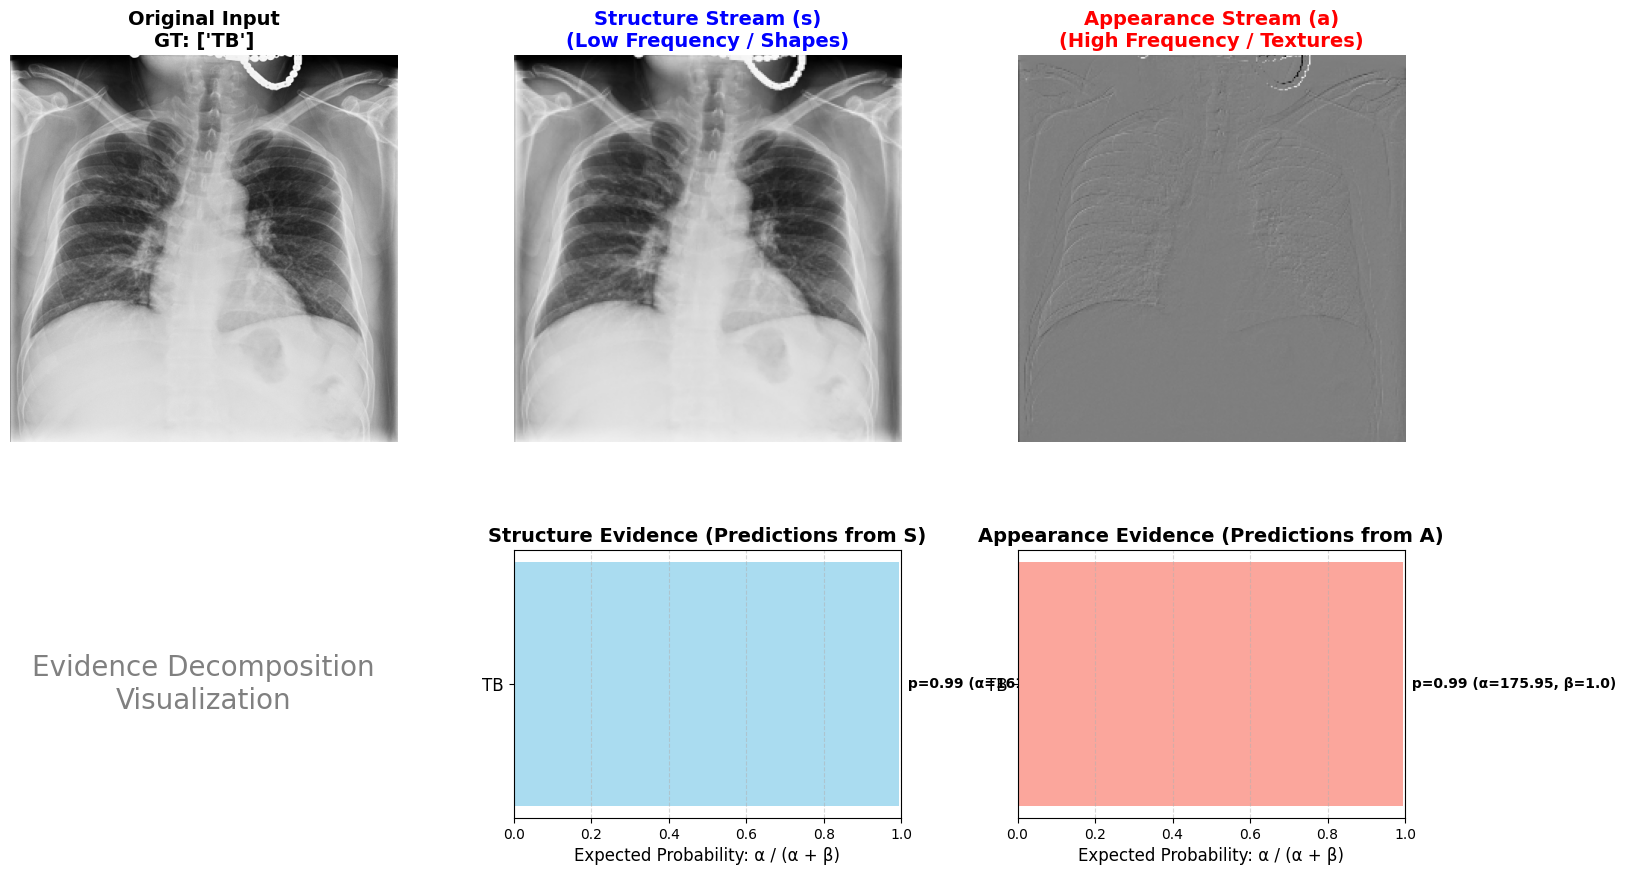

In [7]:
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=5, batch_id=batch_id)

生成可解释性验证图...
[1.]


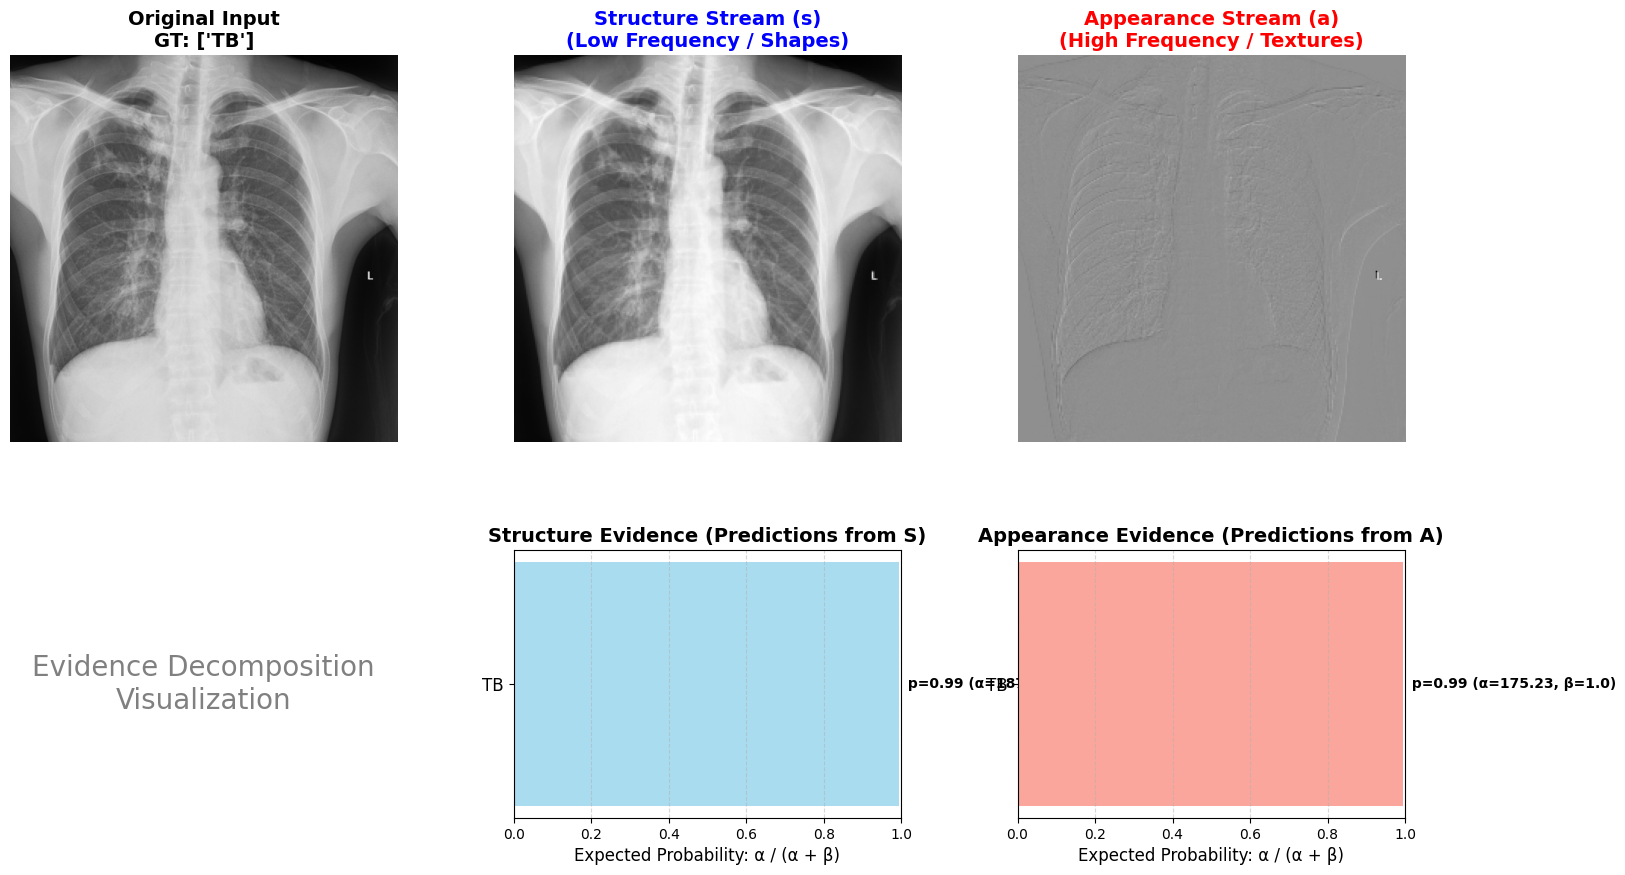

In [8]:
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=10, batch_id=batch_id)

生成可解释性验证图...
[1.]


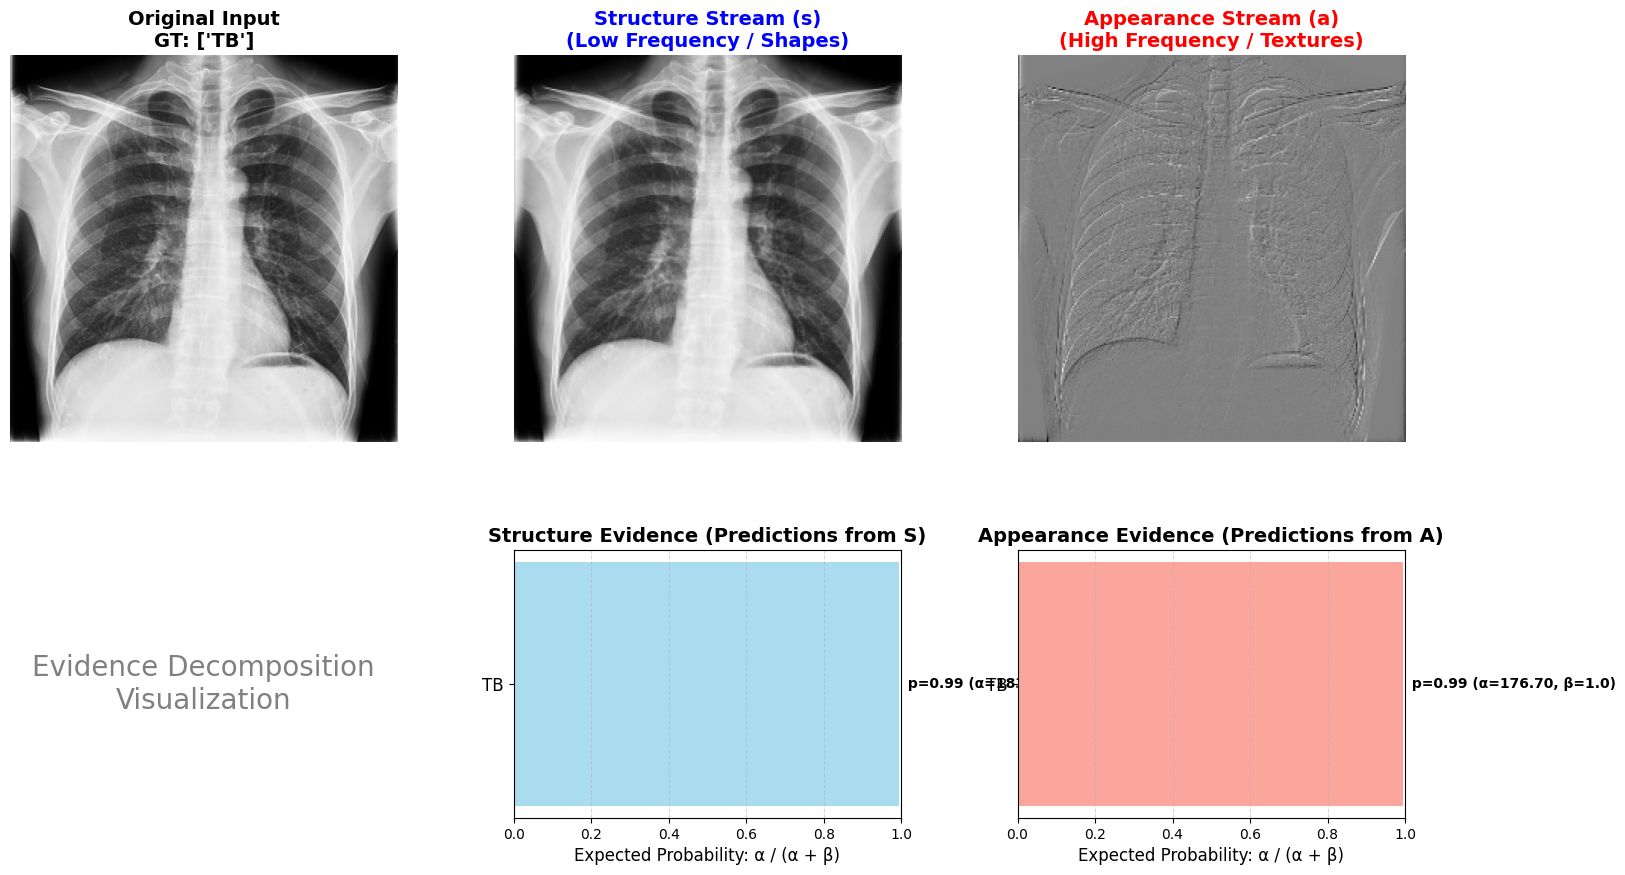

In [9]:
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=15, batch_id=batch_id)

生成可解释性验证图...
[1.]


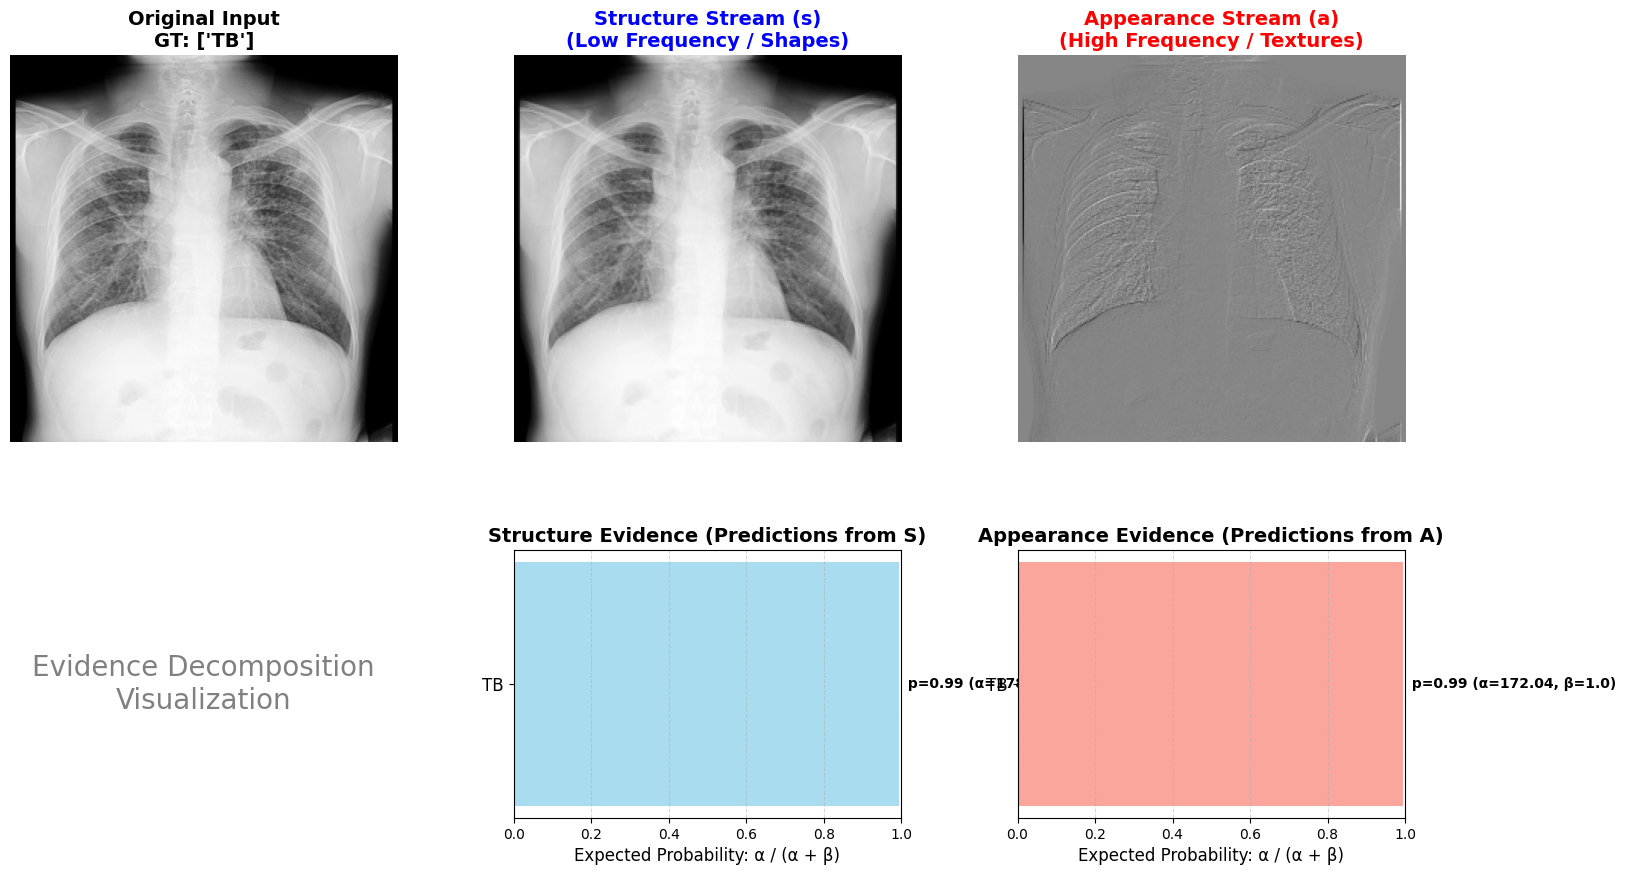

In [10]:
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=20, batch_id=batch_id)

生成可解释性验证图...
[0.]


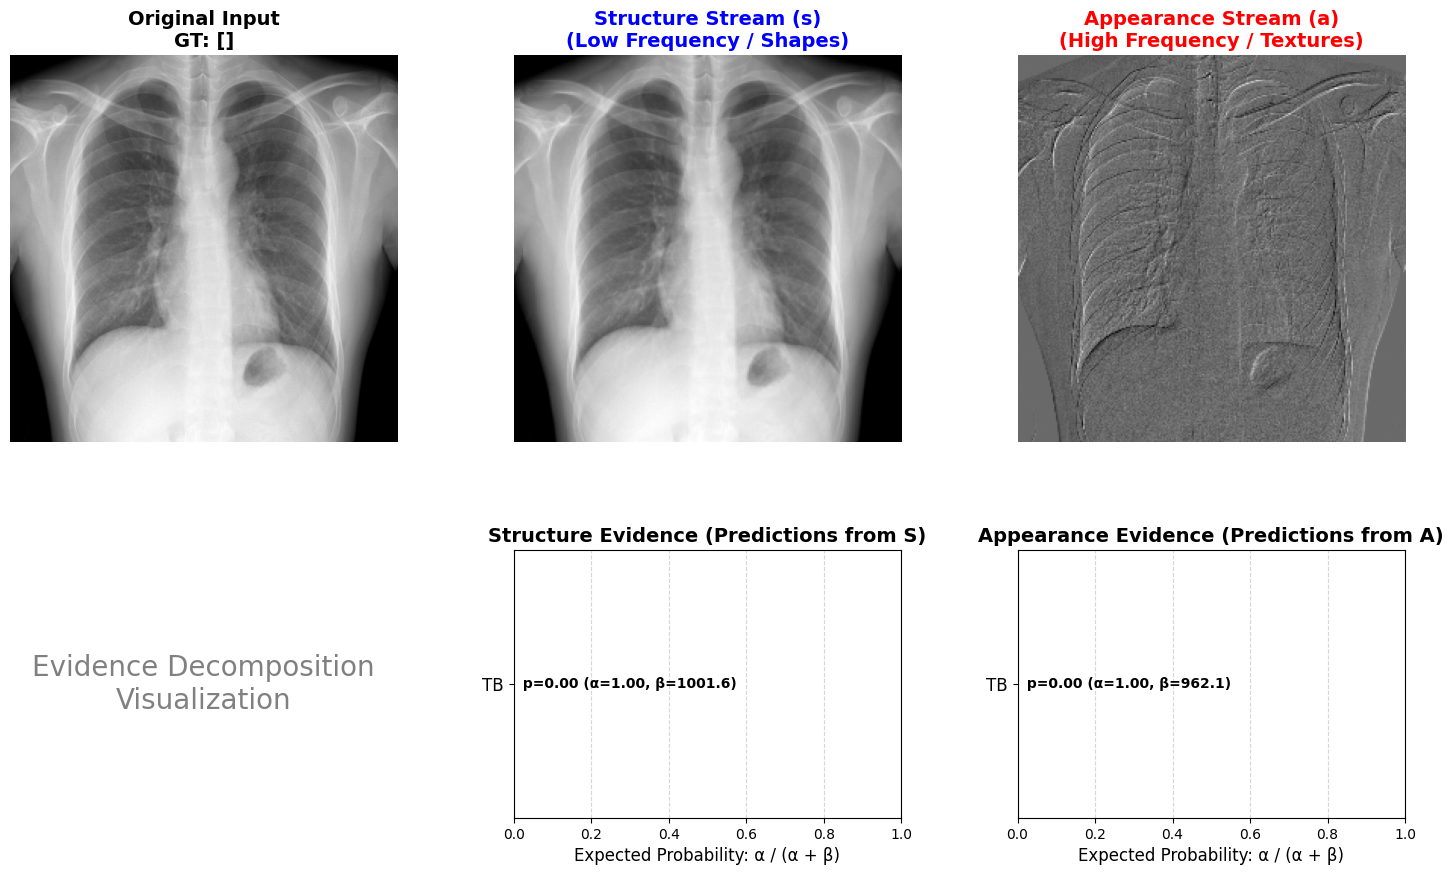

In [11]:
batch_id = 3
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=10, batch_id=batch_id)

生成可解释性验证图...
[0.]


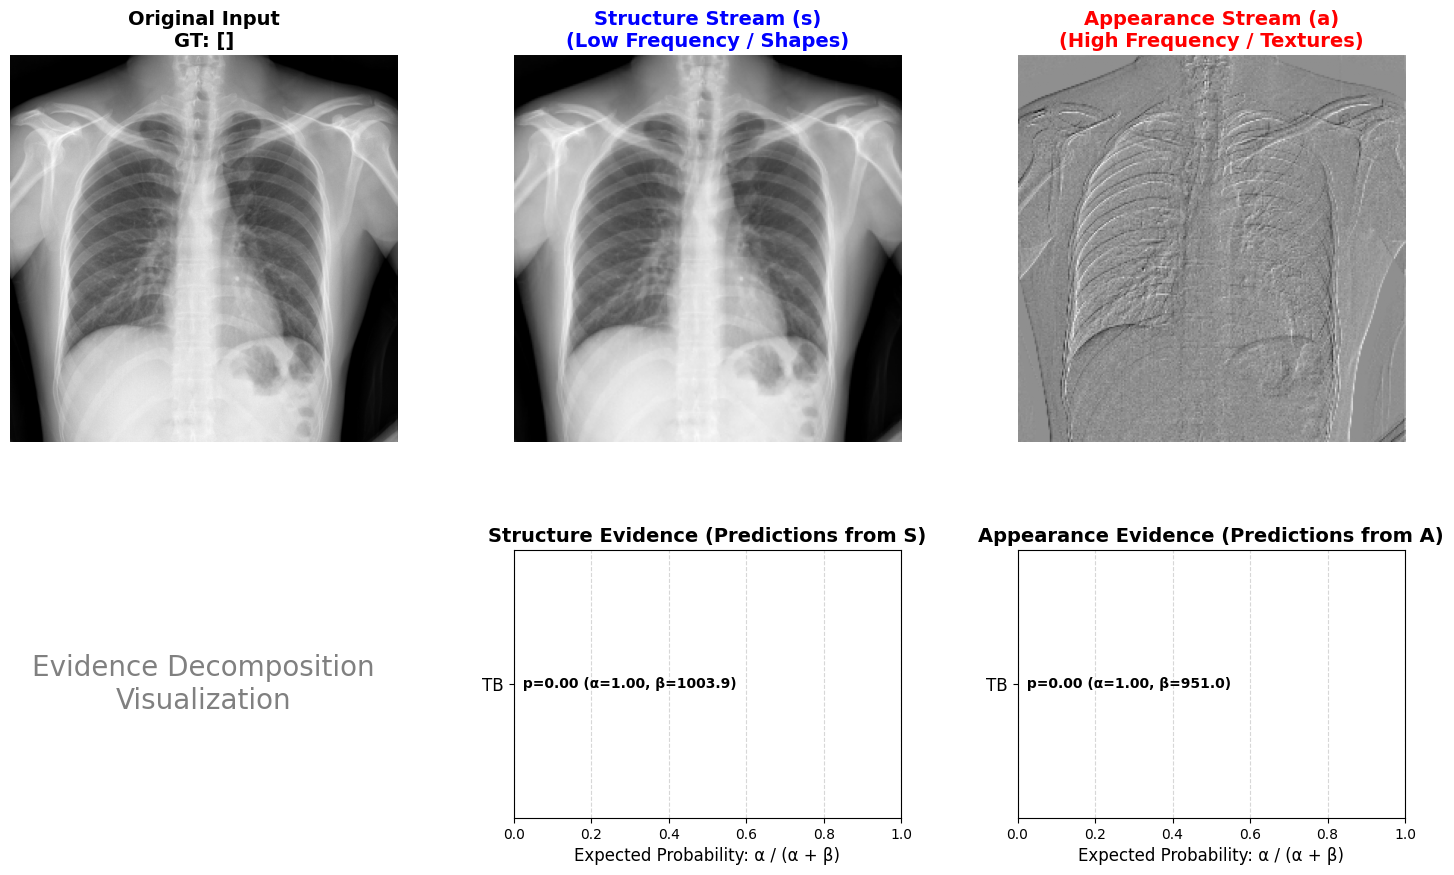

In [12]:
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=20, batch_id=batch_id)

生成可解释性验证图...
[0.]


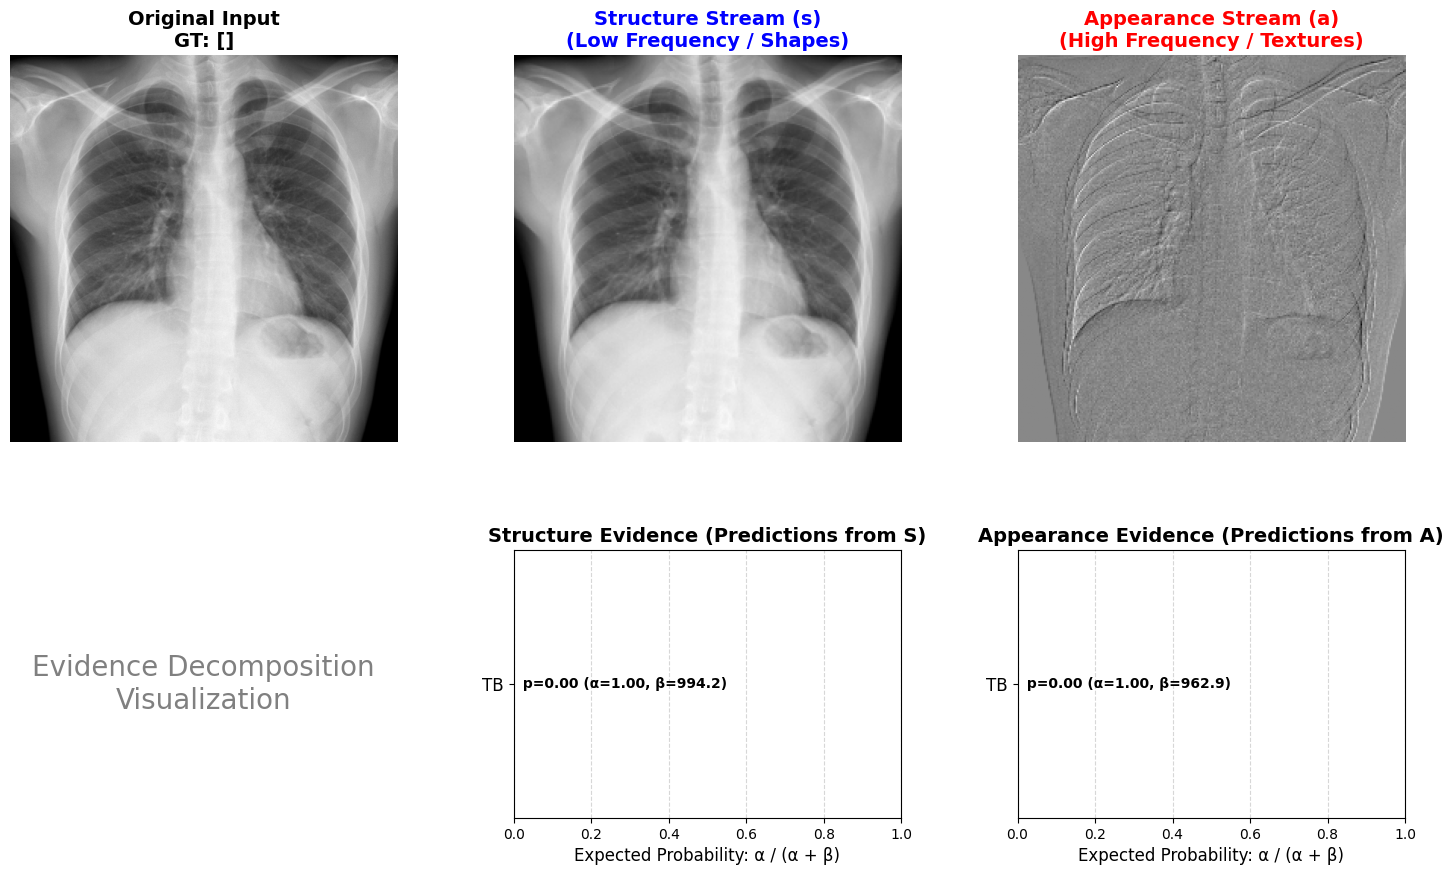

In [13]:
print("生成可解释性验证图...")
visualize_evidence_explainability(final_model, dwt2D, val_loader, my_classes, DEVICE, sample_idx=30, batch_id=batch_id)